Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Make sure you fill in any place that says `YOUR CODE HERE` or "YOUR ANSWER HERE", as well as your name and collaborators below:

In [ ]:
NAME = ""
COLLABORATORS = ""

---

# Assignment 2: Sector Diversification and Portfolio Risk

**Created by: Pengfei Zhao**  
**© 2025 Investment Practice Course**

**DDL: 23:59, Dec 8, 2025.**

**Learning Objectives:**
- Understand the importance of sector diversification in portfolio construction
- Compare efficient frontiers between single-sector and multi-sector portfolios
- Analyze risk decomposition to understand correlation effects
- Demonstrate why "diversification" within a single sector provides limited risk reduction
- Apply portfolio optimization techniques to real stock data

**Key Concept:**
> **"Don't put all your eggs in one basket... and make sure your baskets are in different industries!"**
> 
> Holding multiple stocks from the same sector (e.g., all tech stocks) provides much less diversification benefit than holding stocks from different sectors. This is because stocks in the same sector tend to move together due to common risk factors.

---

## Mathematical Foundation

### Portfolio Variance and Correlation

The portfolio variance for n assets is:

$$\sigma_p^2 = \sum_{i=1}^{n} \sum_{j=1}^{n} w_i w_j \sigma_i \sigma_j \rho_{ij}$$

Where:
- $w_i$ = weight of asset i
- $\sigma_i$ = volatility (standard deviation) of asset i
- $\rho_{ij}$ = correlation coefficient between assets i and j

### Why Sector Diversification Matters

**High Correlation Problem**: Stocks in the same sector typically have high correlations ($\rho \approx 0.7-0.9$) because they:
- Face similar market conditions
- Are affected by the same industry trends
- Respond to common regulatory changes
- Share similar customer bases and supply chains

**Diversification Benefit**: The diversification benefit is measured by:

$$DB = \frac{\text{Weighted Avg Volatility} - \text{Portfolio Volatility}}{\text{Weighted Avg Volatility}} \times 100\%$$

Higher diversification benefits occur when correlations are lower!

---

## Setup and Data Loading

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

# Configure plotting
plt.style.use('default')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
sns.set_palette("husl")
print("="*50)
print("✅ Libraries imported successfully")

### Load Portfolio Data

We will compare two portfolios:

**Portfolio 1 - Tech Sector Only:**
- AAPL (Apple)
- GOOGL (Alphabet/Google)
- MSFT (Microsoft)
- AMZN (Amazon)
- TSLA (Tesla)

**Portfolio 2 - Diversified Sectors:**
- AAPL (Technology)
- JPM (Financial Services)
- JNJ (Healthcare)
- WMT (Consumer Cyclical)
- PG (Consumer Defensive)

In [ ]:
# Load portfolio data
portfolio1_returns = pd.read_csv('portfolio1_tech_sector_returns.csv', index_col=0, parse_dates=True)
portfolio2_returns = pd.read_csv('portfolio2_diversified_sectors_returns.csv', index_col=0, parse_dates=True)

print("\n📈 Portfolio 1 - Tech Sector (All Technology Stocks):")
print(f"   Stocks: {list(portfolio1_returns.columns)}")
print(f"   Data points: {len(portfolio1_returns)}")
print(f"   Date range: {portfolio1_returns.index[0].date()} to {portfolio1_returns.index[-1].date()}")

print("\n📊 Portfolio 2 - Diversified Sectors:")
print(f"   Stocks: {list(portfolio2_returns.columns)}")
print(f"   Data points: {len(portfolio2_returns)}")
print(f"   Sectors: Technology, Finance, Healthcare, Consumer Cyclical, Consumer Defensive")

---

## Exercise 1: Calculate Basic Portfolio Statistics

For each portfolio, calculate:
1. Annualized mean returns (multiply daily returns by 252)
2. Annualized volatilities (multiply daily std by √252)
3. Correlation matrices
4. Covariance matrices (annualized)

Compare the correlation structures between the two portfolios.

**Hint**: Use pandas methods `.mean()`, `.std()`, `.corr()`, and `.cov()`

In [ ]:
# Portfolio 1: Tech Sector
#CODE HERE - Calculate annualized returns (mean * 252)
p1_annual_returns = None

#CODE HERE - Calculate annualized volatilities (std * sqrt(252))
p1_annual_volatilities = None

#CODE HERE - Calculate correlation matrix
p1_correlation_matrix = None

#CODE HERE - Calculate covariance matrix (annualized: cov * 252)
p1_covariance_matrix = None

print("\n📊 PORTFOLIO 1 - TECH SECTOR STATISTICS:")
print("="*50)
print("\nAnnualized Returns:")
print(p1_annual_returns.apply(lambda x: f"{x:.2%}"))
print("\nAnnualized Volatilities:")
print(p1_annual_volatilities.apply(lambda x: f"{x:.2%}"))
print(f"\nAverage Correlation: {p1_correlation_matrix.values[np.triu_indices_from(p1_correlation_matrix.values, k=1)].mean():.3f}")

# Portfolio 2: Diversified
#CODE HERE - Calculate annualized returns for portfolio 2
p2_annual_returns = None

#CODE HERE - Calculate annualized volatilities for portfolio 2
p2_annual_volatilities = None

#CODE HERE - Calculate correlation matrix for portfolio 2
p2_correlation_matrix = None

#CODE HERE - Calculate covariance matrix for portfolio 2 (annualized)
p2_covariance_matrix = None

print("\n\n📊 PORTFOLIO 2 - DIVERSIFIED SECTORS STATISTICS:")
print("="*50)
print("\nAnnualized Returns:")
print(p2_annual_returns.apply(lambda x: f"{x:.2%}"))
print("\nAnnualized Volatilities:")
print(p2_annual_volatilities.apply(lambda x: f"{x:.2%}"))
print(f"\nAverage Correlation: {p2_correlation_matrix.values[np.triu_indices_from(p2_correlation_matrix.values, k=1)].mean():.3f}")

### Visualize Correlation Matrices

**Question**: Which portfolio has higher average correlations? What does this imply for diversification potential?

In [ ]:
# Visualize correlation matrices side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

#CODE HERE - Create heatmap for Portfolio 1 correlation matrix on ax1
# Use sns.heatmap() with parameters: annot=True, fmt='.3f', cmap='RdYlBu_r', center=0, square=True

ax1.set_title('Portfolio 1: Tech Sector\nCorrelation Matrix', fontsize=14, fontweight='bold')

#CODE HERE - Create heatmap for Portfolio 2 correlation matrix on ax2
# Use the same parameters as Portfolio 1

ax2.set_title('Portfolio 2: Diversified Sectors\nCorrelation Matrix', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n💡 Key Observation:")
print(f"   Tech Sector Avg Correlation: {p1_correlation_matrix.values[np.triu_indices_from(p1_correlation_matrix.values, k=1)].mean():.3f}")
print(f"   Diversified Avg Correlation: {p2_correlation_matrix.values[np.triu_indices_from(p2_correlation_matrix.values, k=1)].mean():.3f}")
#CODE HERE - Add your interpretation: Which portfolio shows higher correlations? What does this mean?

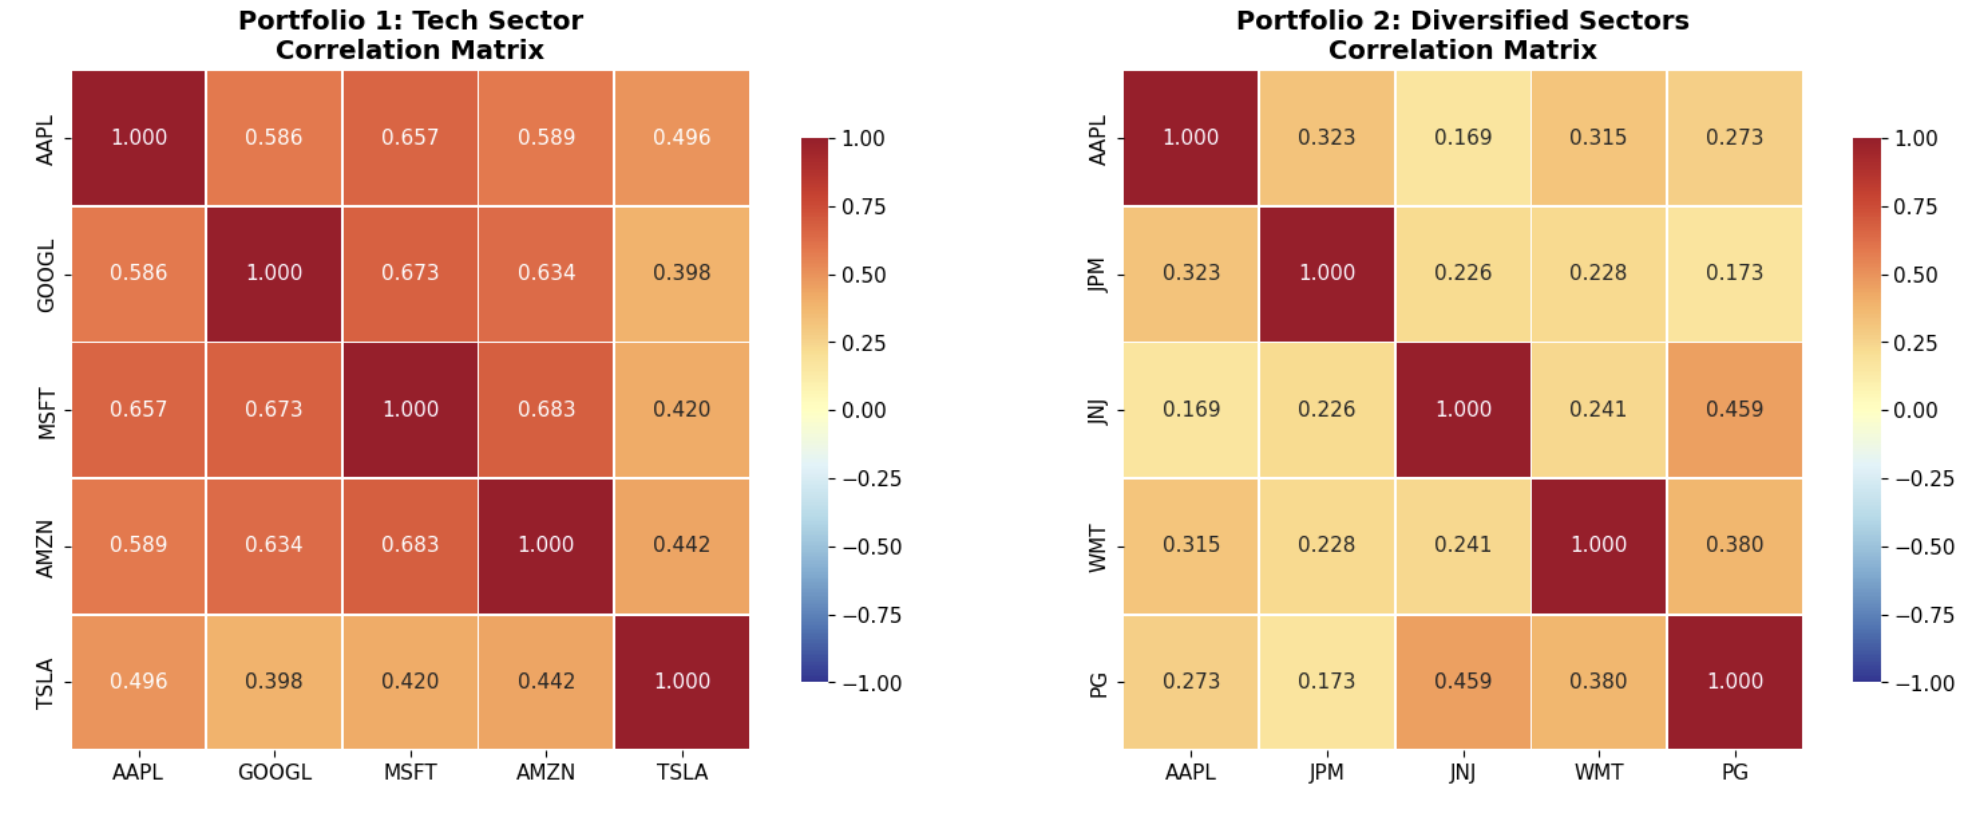

---

## Exercise 2: Generate Efficient Frontiers

For each portfolio, generate the efficient frontier by:
1. Defining target returns from minimum to maximum
2. For each target return, minimize portfolio variance subject to:
   - Weights sum to 1
   - Portfolio return equals target return
   - No short selling (weights ≥ 0)
3. Plot both efficient frontiers on the same figure

**Expected Result**: The diversified portfolio should have a more favorable efficient frontier (lower risk for same return).

In [ ]:
def portfolio_volatility(weights, cov_matrix):
    """Calculate portfolio volatility"""
    #CODE HERE - Calculate portfolio volatility using the formula: sqrt(w^T * Cov * w)
    return None

def portfolio_return(weights, expected_returns):
    """Calculate portfolio expected return"""
    #CODE HERE - Calculate portfolio return: sum of (weight * return) for each asset
    return None

def generate_efficient_frontier(expected_returns, cov_matrix, num_portfolios=30):
    """
    Generate efficient frontier points
    
    For each target return, find the portfolio with minimum variance
    subject to: weights sum to 1, return = target, weights >= 0
    """
    n_assets = len(expected_returns)
    
    # Define target returns range
    #CODE HERE - Create array of target returns from min to max using np.linspace
    min_ret = None  # Hint: use expected_returns.min()
    max_ret = None  # Hint: use expected_returns.max()
    target_returns = None  # Hint: np.linspace(min_ret, max_ret, num_portfolios)
    
    efficient_portfolios = []
    
    for target_return in target_returns:
        # Constraints
        constraints = [
            #CODE HERE - Add constraint: weights sum to 1
            {'type': 'eq', 'fun': lambda w: None},
            #CODE HERE - Add constraint: portfolio return equals target return
            {'type': 'eq', 'fun': lambda w, tr=target_return: None}
        ]
        
        # Bounds: no short selling
        bounds = tuple((0, 1) for _ in range(n_assets))
        
        # Initial guess: equal weights
        initial_weights = np.array([1/n_assets] * n_assets)
        
        # Minimize variance
        #CODE HERE - Use minimize() to find optimal weights that minimize portfolio_volatility^2
        result = None
        
        if result.success:
            vol = portfolio_volatility(result.x, cov_matrix)
            ret = portfolio_return(result.x, expected_returns)
            efficient_portfolios.append({
                'return': ret,
                'volatility': vol,
                'weights': result.x
            })
    
    return efficient_portfolios

print("\n🔄 Generating efficient frontiers...")
print("   This may take a moment...\n")

# Generate efficient frontiers
#CODE HERE - Generate efficient frontier for Portfolio 1
ef1 = None
print(f"✅ Portfolio 1 (Tech): {len(ef1)} efficient points generated")

#CODE HERE - Generate efficient frontier for Portfolio 2
ef2 = None
print(f"✅ Portfolio 2 (Diversified): {len(ef2)} efficient points generated")

### Plot Efficient Frontiers

Compare the two efficient frontiers side by side.

In [ ]:
# Extract data for plotting
#CODE HERE - Extract volatilities and returns from ef1
ef1_vols = None  # Hint: list comprehension [p['volatility'] for p in ef1]
ef1_rets = None  # Hint: list comprehension [p['return'] for p in ef1]

#CODE HERE - Extract volatilities and returns from ef2
ef2_vols = None
ef2_rets = None

# Create plot
fig, ax = plt.subplots(figsize=(14, 9))

#CODE HERE - Plot efficient frontier for Portfolio 1 (red line)
# Use ax.plot() with parameters: linewidth=3, label='Portfolio 1: Tech Sector', color='red'

#CODE HERE - Plot efficient frontier for Portfolio 2 (blue line)
# Use ax.plot() with parameters: linewidth=3, label='Portfolio 2: Diversified Sectors', color='blue'

# Plot individual assets for Portfolio 1
for i, stock in enumerate(portfolio1_returns.columns):
    ax.scatter(p1_annual_volatilities[i], p1_annual_returns[i], 
              s=100, alpha=0.6, color='red', marker='o', edgecolors='darkred', linewidth=1.5)
    ax.annotate(stock, (p1_annual_volatilities[i], p1_annual_returns[i]),
               xytext=(8, 8), textcoords='offset points', fontsize=10, 
               color='darkred', fontweight='bold')

# Plot individual assets for Portfolio 2
for i, stock in enumerate(portfolio2_returns.columns):
    ax.scatter(p2_annual_volatilities[i], p2_annual_returns[i], 
              s=100, alpha=0.6, color='blue', marker='s', edgecolors='darkblue', linewidth=1.5)
    ax.annotate(stock, (p2_annual_volatilities[i], p2_annual_returns[i]),
               xytext=(8, -12), textcoords='offset points', fontsize=10, 
               color='darkblue', fontweight='bold')

ax.set_xlabel('Portfolio Volatility (Annual)', fontsize=13, fontweight='bold')
ax.set_ylabel('Expected Return (Annual)', fontsize=13, fontweight='bold')
ax.set_title('Efficient Frontiers Comparison:\nTech Sector vs Diversified Sectors', 
            fontsize=15, fontweight='bold', pad=20)
ax.legend(fontsize=12, loc='upper left')
ax.grid(True, alpha=0.3, linestyle='--')

# Format axes as percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0%}'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: f'{y:.0%}'))

plt.tight_layout()
plt.show()

#CODE HERE - Write your observations about the two efficient frontiers
print("\n💡 Your Observations:")
print("   1. Which efficient frontier is more favorable (further left)?")
print("   2. What does this tell you about sector diversification?")
print("   3. For a target return of 15%, which portfolio has lower risk?")

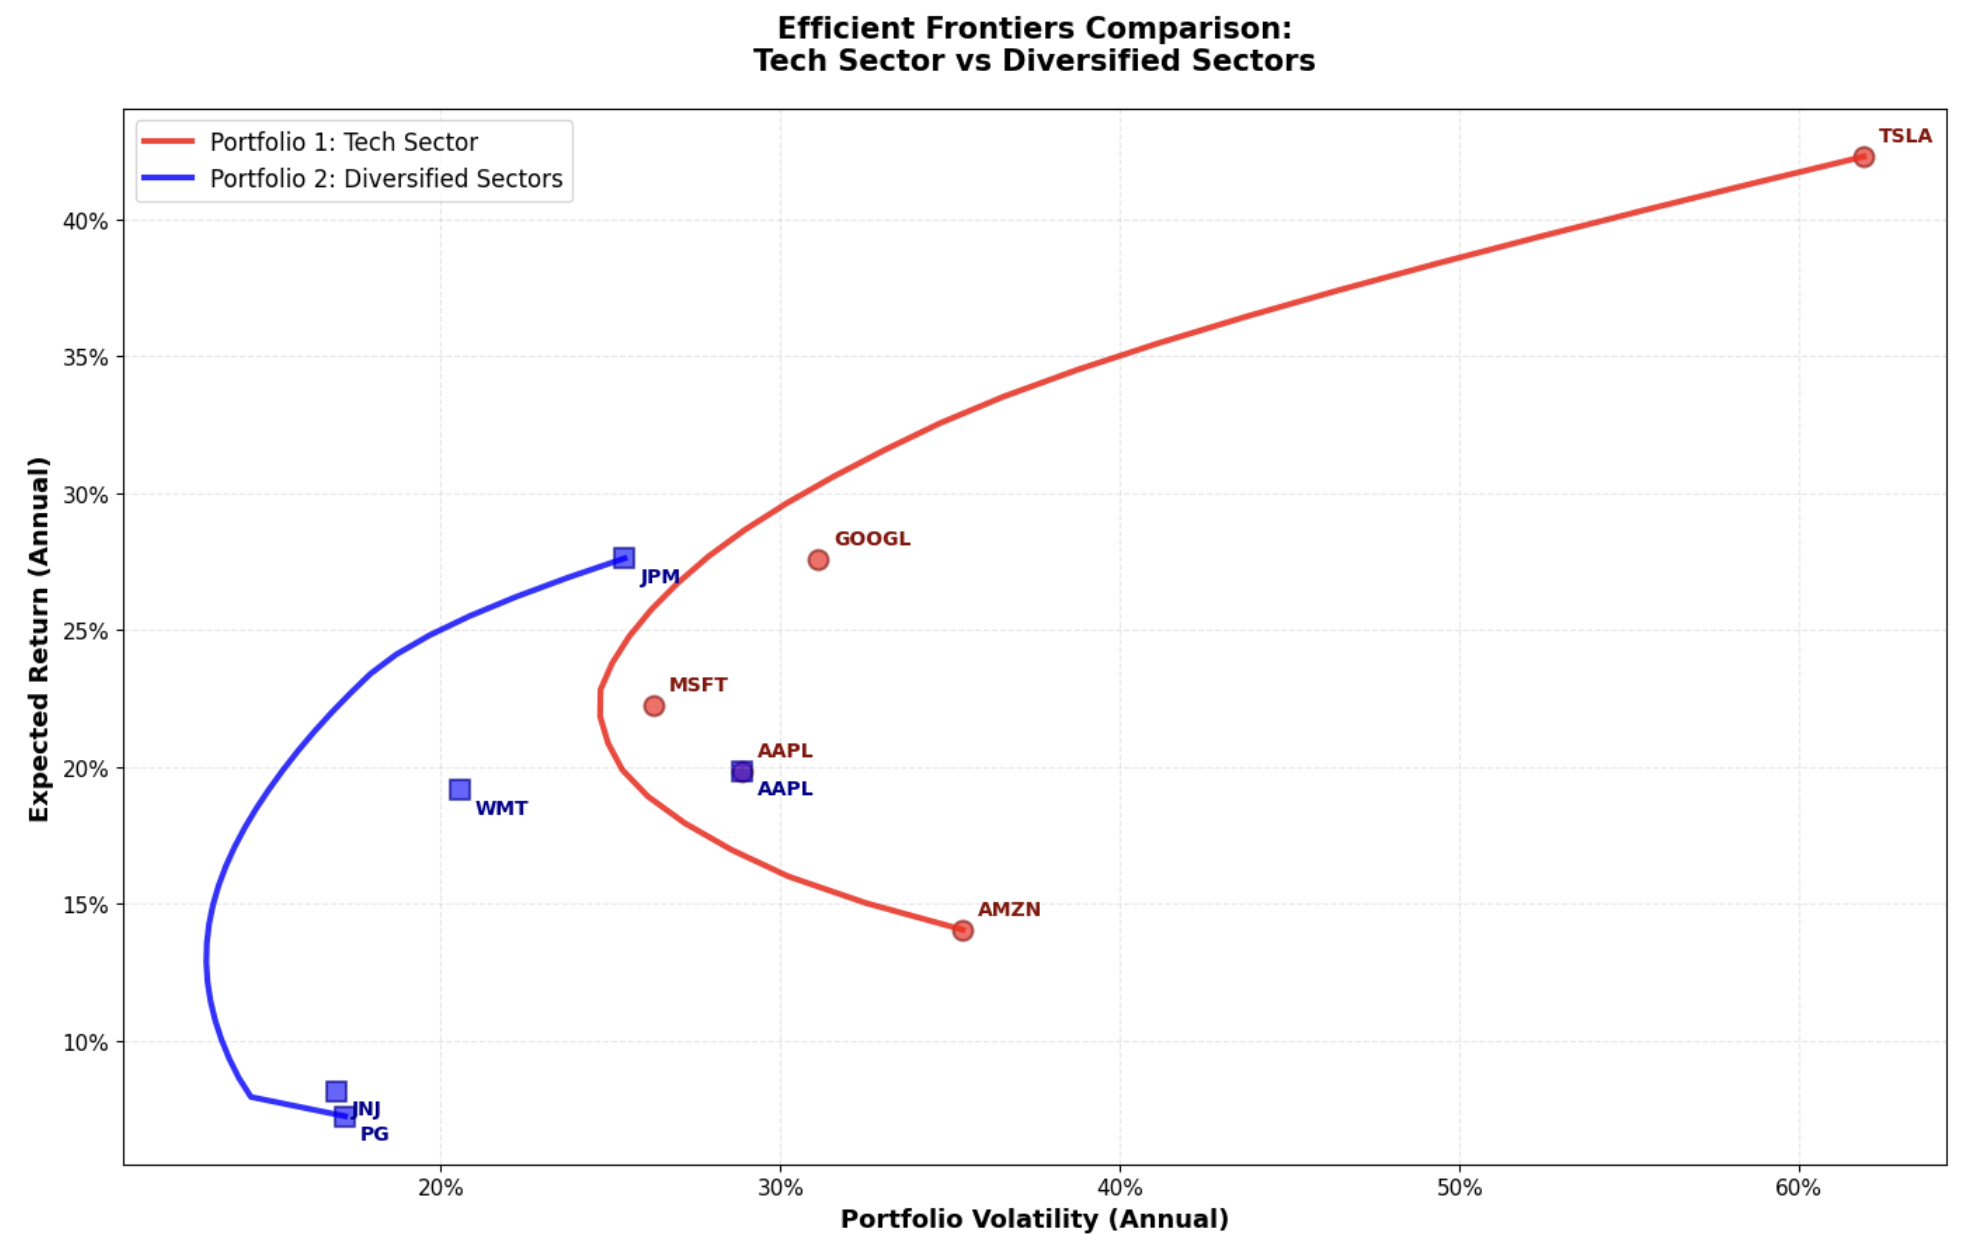

---

## Exercise 3: Risk Decomposition Analysis

Using the equal-weighted portfolios (20% in each stock), perform risk decomposition analysis:

1. Calculate marginal risk contributions for each asset
2. Calculate total risk contributions
3. Decompose variance into:
   - Individual asset variance contributions
   - Interaction (covariance) contributions
4. Compare the risk decomposition between the two portfolios

**Expected Finding**: The tech portfolio will have higher interaction variance (due to high correlations), while the diversified portfolio benefits from lower correlation effects.

In [ ]:
def risk_decomposition_analysis(weights, cov_matrix, asset_names):
    """
    Perform comprehensive risk decomposition analysis
    """
    weights = np.array(weights)
    
    #CODE HERE - Calculate portfolio variance: w^T * Cov * w
    portfolio_variance = None
    
    #CODE HERE - Calculate portfolio volatility: sqrt(variance)
    portfolio_volatility = None
    
    #CODE HERE - Calculate marginal risk contributions: (Cov * w) / portfolio_volatility
    marginal_contrib = None
    
    #CODE HERE - Calculate risk contributions: weights * marginal_contrib
    risk_contrib = None
    
    #CODE HERE - Calculate risk contributions as percentages
    risk_contrib_pct = None
    
    # Component risk analysis
    component_analysis = []
    
    for i, asset in enumerate(asset_names):
        #CODE HERE - Calculate individual variance contribution: w_i^2 * Cov[i,i]
        individual_variance = None
        
        #CODE HERE - Calculate interaction variance with other assets
        # Sum over all j != i: w_i * w_j * Cov[i,j]
        interaction_variance = 0
        for j in range(len(weights)):
            if i != j:
                interaction_variance += None  # Add the covariance term
        
        component_analysis.append({
            'Asset': asset,
            'Weight %': weights[i] * 100,
            'Marginal Risk Contrib': marginal_contrib[i],
            'Risk Contribution': risk_contrib[i],
            'Risk Contrib %': risk_contrib_pct[i],
            'Individual Variance': individual_variance,
            'Interaction Variance': interaction_variance,
            'Risk Ratio': risk_contrib_pct[i] / (weights[i] * 100)
        })
    
    return {
        'portfolio_volatility': portfolio_volatility,
        'portfolio_variance': portfolio_variance,
        'component_analysis': component_analysis,
        'total_individual_variance': sum([c['Individual Variance'] for c in component_analysis]),
        'total_interaction_variance': sum([c['Interaction Variance'] for c in component_analysis]) / 2
    }

# Equal weights for both portfolios
n_assets = 5
equal_weights = np.array([1/n_assets] * n_assets)

print("\n📊 RISK DECOMPOSITION ANALYSIS")
print("="*50)
print(f"\nUsing equal-weighted portfolios: {equal_weights[0]:.1%} per asset\n")

# Portfolio 1 analysis
#CODE HERE - Perform risk decomposition for Portfolio 1
p1_risk_decomp = None

print("\n🔴 PORTFOLIO 1 - TECH SECTOR:")
print(f"   Portfolio Volatility: {p1_risk_decomp['portfolio_volatility']:.2%}")
print("\n   Component Analysis:")
df1 = pd.DataFrame(p1_risk_decomp['component_analysis'])
print(df1[['Asset', 'Weight %', 'Risk Contrib %', 'Risk Ratio']].round(2).to_string(index=False))

# Variance decomposition
#CODE HERE - Calculate percentage of variance from individual risk
p1_individual_pct = None
#CODE HERE - Calculate percentage of variance from interactions
p1_interaction_pct = None

print(f"\n   Variance Decomposition:")
print(f"     Individual Asset Risk: {p1_individual_pct:.1f}%")
print(f"     Asset Interactions: {p1_interaction_pct:.1f}%")

# Portfolio 2 analysis
#CODE HERE - Perform risk decomposition for Portfolio 2
p2_risk_decomp = None

print("\n\n🔵 PORTFOLIO 2 - DIVERSIFIED SECTORS:")
print(f"   Portfolio Volatility: {p2_risk_decomp['portfolio_volatility']:.2%}")
print("\n   Component Analysis:")
df2 = pd.DataFrame(p2_risk_decomp['component_analysis'])
print(df2[['Asset', 'Weight %', 'Risk Contrib %', 'Risk Ratio']].round(2).to_string(index=False))

# Variance decomposition
#CODE HERE - Calculate percentage of variance from individual risk for Portfolio 2
p2_individual_pct = None
#CODE HERE - Calculate percentage of variance from interactions for Portfolio 2
p2_interaction_pct = None

print(f"\n   Variance Decomposition:")
print(f"     Individual Asset Risk: {p2_individual_pct:.1f}%")
print(f"     Asset Interactions: {p2_interaction_pct:.1f}%")

### Visualize Risk Decomposition

Compare the variance decomposition between the two portfolios.

In [ ]:
# Visualization of risk decomposition comparison
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

#CODE HERE - Create pie chart for Portfolio 1 variance decomposition on ax1
# Show individual vs interaction variance percentages

ax1.set_title('Portfolio 1: Tech Sector\nVariance Decomposition', fontsize=14, fontweight='bold')

#CODE HERE - Create pie chart for Portfolio 2 variance decomposition on ax2

ax2.set_title('Portfolio 2: Diversified Sectors\nVariance Decomposition', fontsize=14, fontweight='bold')

#CODE HERE - Create bar chart for Portfolio 1 risk contributions by asset on ax3
# Add horizontal line at 20% (equal weight reference)

ax3.set_ylabel('Risk Contribution (%)', fontsize=12, fontweight='bold')
ax3.set_title('Portfolio 1: Tech Sector\nRisk Contribution by Asset', fontsize=14, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='y')

#CODE HERE - Create bar chart for Portfolio 2 risk contributions by asset on ax4

ax4.set_ylabel('Risk Contribution (%)', fontsize=12, fontweight='bold')
ax4.set_title('Portfolio 2: Diversified Sectors\nRisk Contribution by Asset', fontsize=14, fontweight='bold')
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

#CODE HERE - Write your analysis of the risk decomposition results
print("\n💡 Your Analysis:")
print("   1. Which portfolio has higher interaction variance?")
print("   2. What does this tell you about correlations within each portfolio?")
print("   3. How much risk reduction did sector diversification achieve?")

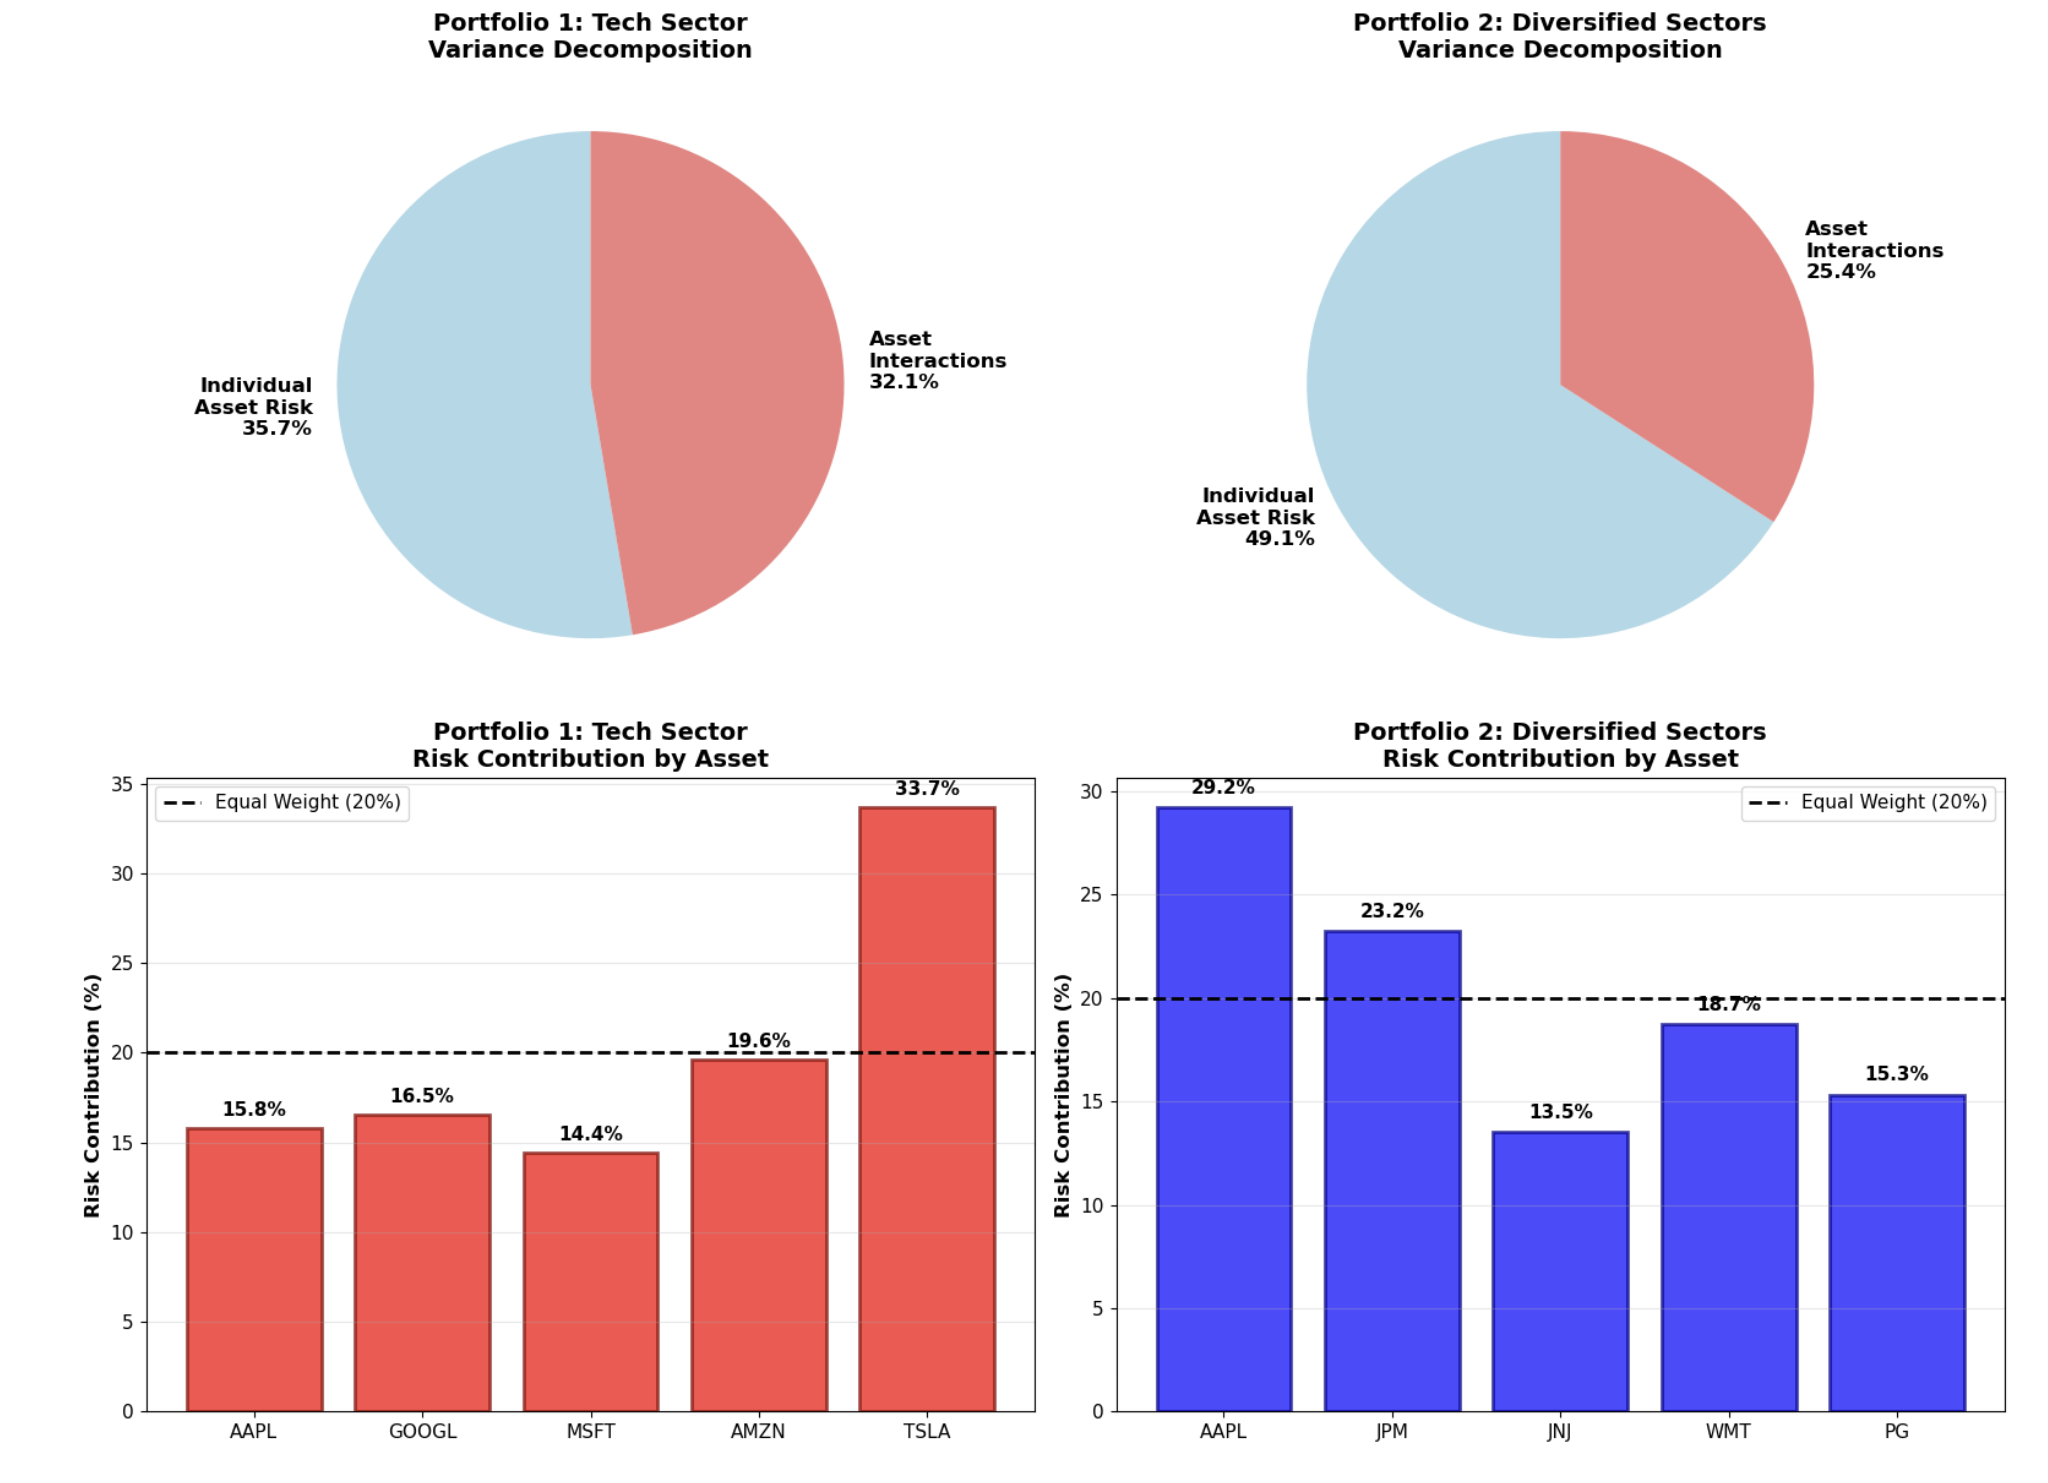

---

## Exercise 4: Diversification Benefit Calculation

Calculate the diversification benefit for both portfolios using equal weights:

$$\text{Diversification Benefit} = \frac{\text{Weighted Avg Volatility} - \text{Portfolio Volatility}}{\text{Weighted Avg Volatility}} \times 100\%$$

Compare the diversification benefits between the two portfolios.

In [ ]:
# Calculate diversification benefits
print("\n📊 DIVERSIFICATION BENEFIT ANALYSIS")
print("="*70)

# Portfolio 1: Tech Sector
#CODE HERE - Calculate weighted average volatility for Portfolio 1
p1_weighted_avg_vol = None  # Hint: np.dot(equal_weights, p1_annual_volatilities)

#CODE HERE - Get actual portfolio volatility from risk decomposition
p1_portfolio_vol = None

#CODE HERE - Calculate diversification benefit
p1_div_benefit = None  # Use the formula above

print("\n🔴 Portfolio 1 - Tech Sector:")
print(f"   Weighted Average Volatility: {p1_weighted_avg_vol:.2%}")
print(f"   Actual Portfolio Volatility: {p1_portfolio_vol:.2%}")
print(f"   Diversification Benefit: {p1_div_benefit:.2f}%")

# Portfolio 2: Diversified
#CODE HERE - Calculate weighted average volatility for Portfolio 2
p2_weighted_avg_vol = None

#CODE HERE - Get actual portfolio volatility
p2_portfolio_vol = None

#CODE HERE - Calculate diversification benefit
p2_div_benefit = None

print("\n🔵 Portfolio 2 - Diversified Sectors:")
print(f"   Weighted Average Volatility: {p2_weighted_avg_vol:.2%}")
print(f"   Actual Portfolio Volatility: {p2_portfolio_vol:.2%}")
print(f"   Diversification Benefit: {p2_div_benefit:.2f}%")

print("\n" + "="*70)
#CODE HERE - Compare the diversification benefits and write conclusions
print(f"\n✅ Diversification Benefit Comparison:")
print(f"   Tech Sector: {p1_div_benefit:.2f}% risk reduction")
print(f"   Diversified: {p2_div_benefit:.2f}% risk reduction")

# Visualize diversification benefits
fig, ax = plt.subplots(figsize=(10, 6))

#CODE HERE - Create bar chart comparing diversification benefits
# Show both portfolios side by side

ax.set_ylabel('Diversification Benefit (%)', fontsize=13, fontweight='bold')
ax.set_title('Diversification Benefit Comparison\n(Higher is Better)', 
            fontsize=15, fontweight='bold', pad=20)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

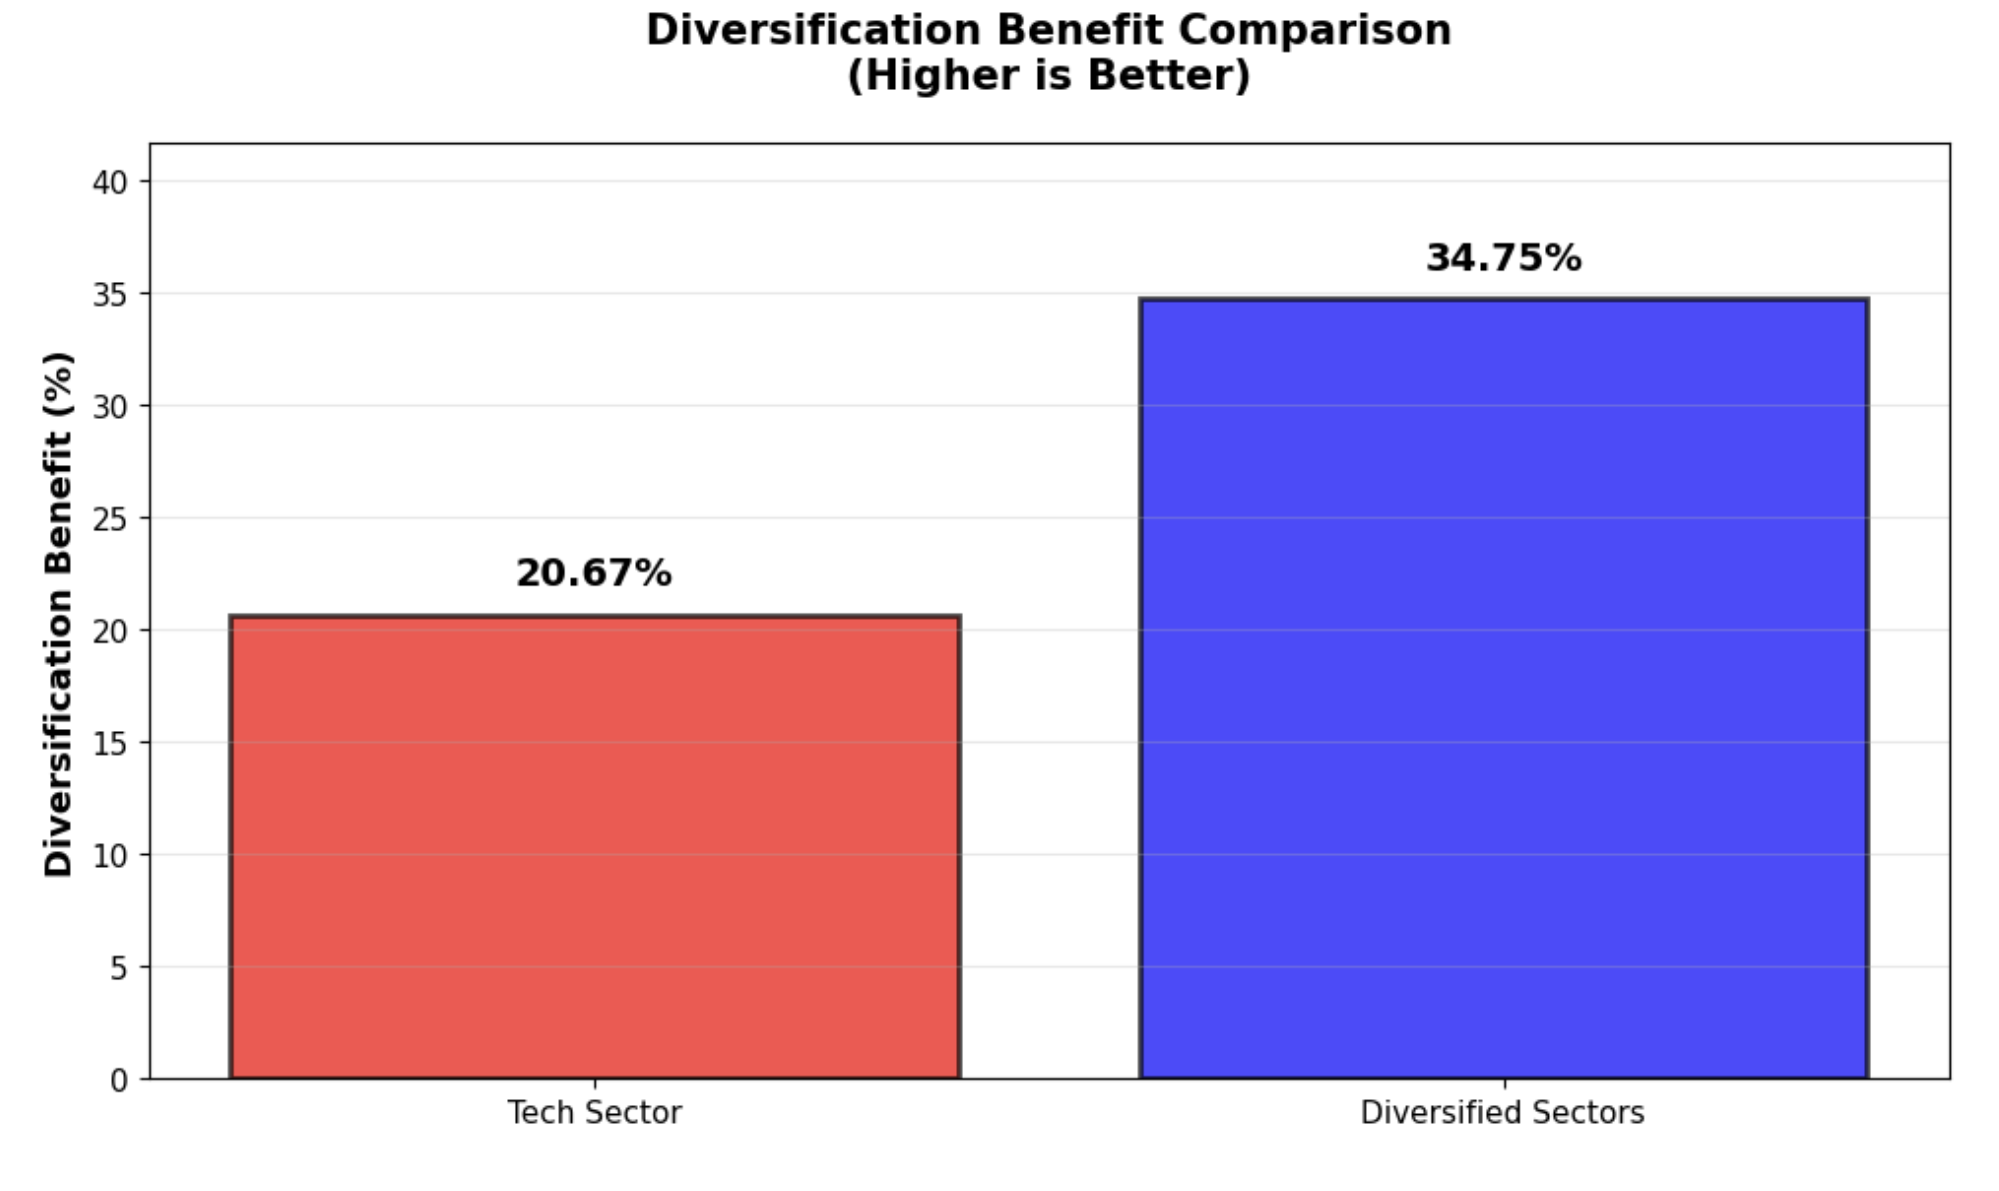

---

## Summary and Conclusions

### 🎯 Key Takeaways:

1. **Sector Concentration Risk**:
   - Stocks within the same sector are highly correlated
   - High correlations limit diversification benefits
   - "5 tech stocks ≠ true diversification"

2. **Efficient Frontier Analysis**:
   #CODE HERE - Write what you observed about the efficient frontiers

3. **Risk Decomposition Insights**:
   #CODE HERE - Write what the risk decomposition analysis revealed

4. **Practical Implications**:
   #CODE HERE - List 3-5 practical lessons for portfolio construction

### 📈 Your Conclusions:

#CODE HERE - Write a paragraph summarizing why sector diversification matters

---

### 🎓 Assignment Complete!

**Key Formula to Remember**:

$$\sigma_p^2 = \sum_{i=1}^{n} \sum_{j=1}^{n} w_i w_j \sigma_i \sigma_j \rho_{ij}$$

When $\rho_{ij}$ is high (same sector), portfolio risk remains high.

When $\rho_{ij}$ is lower (different sectors), portfolio risk is reduced!

**Next Steps**: Apply these concepts to your own portfolio. Check your sector exposures and correlation structure. Are you truly diversified?